Huidige map: c:\Users\Gkain\OneDrive\Documenten\PythonCrashCourse\computer vision
Aantal afbeeldingen: 240


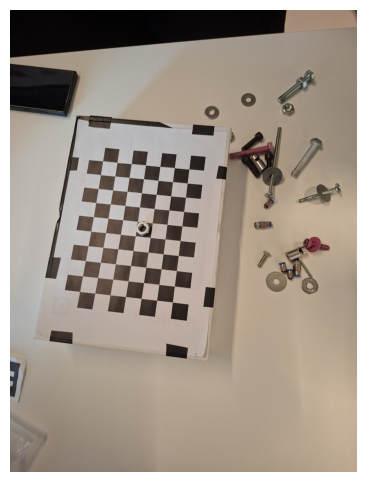

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Controleer waar het notebook wordt uitgevoerd
print("Huidige map:", Path.cwd())

# Locatie van de afbeeldingen
DATASET_PATH = Path("dataset/images")

# Zoek afbeeldingen
image_paths = sorted(DATASET_PATH.glob("*.jpg"))

print("Aantal afbeeldingen:", len(image_paths))

if len(image_paths) > 0:
    image = cv2.imread(str(image_paths[0]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.show()
else:
    print("Geen afbeeldingen gevonden! Controleer het pad.")

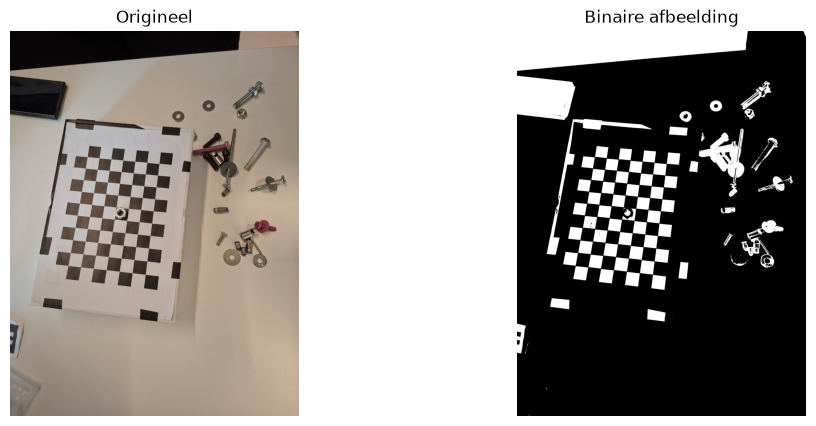

In [12]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Ruis verminderen
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Onderdelen onderscheiden van achtergrond
_, binary = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Kleine ruis verwijderen
kernel = np.ones((3, 3), np.uint8)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Origineel")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binaire afbeelding")
plt.axis("off")

plt.show()

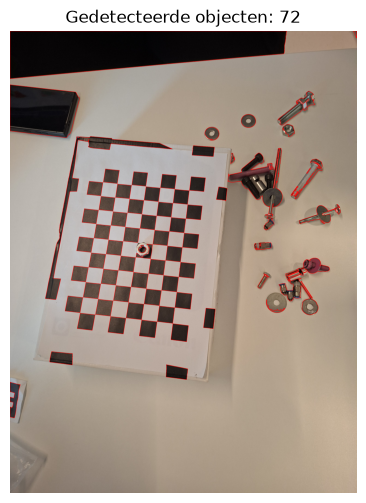

In [13]:
contours, _ = cv2.findContours(
    binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Kleine contouren verwijderen
contours = [c for c in contours if cv2.contourArea(c) > 150]

result = image.copy()

cv2.drawContours(result, contours, -1, (255, 0, 0), 2)

plt.figure(figsize=(10, 6))
plt.imshow(result)
plt.title(f"Gedetecteerde objecten: {len(contours)}")
plt.axis("off")
plt.show()